# Outliers and capped values

**Outliers** are data points that lie far from the bulk of the distribution. They may be errors, rare but valid observations, or members of a genuinely different population, and each case calls for a different treatment. Before deciding anything, it is worth checking whether someone already handled them before the data reached us.

The California housing dataset is a good example: some variables have been **capped**, i.e. values exceeding a certain threshold were replaced with that threshold value. This is evident in the histograms of `housing_median_age` (capped at 52) and `median_house_value` (capped at 500,001 USD), where we see a tall bar at the maximum value.

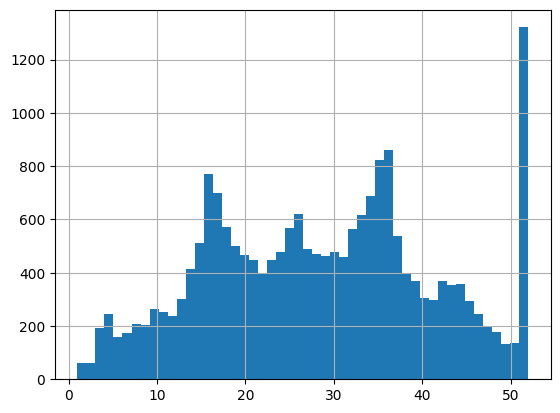

In [ ]:
import pandas as pd

housing = pd.read_csv("../data/housing.csv")
housing["housing_median_age"].hist(bins=50);

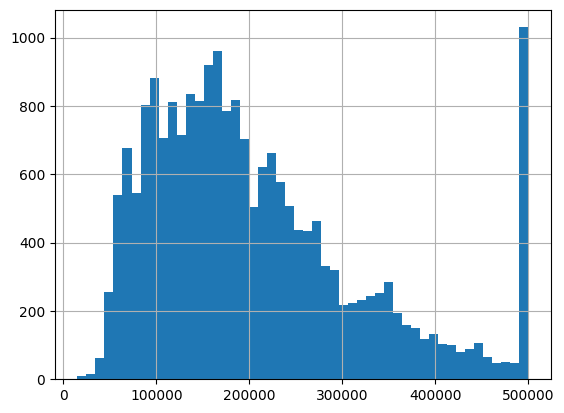

In [ ]:
housing["median_house_value"].hist(bins=50);

Capping the target is a particular problem, since the model may erroneously learn that prices never exceed that limit. If we need accurate predictions beyond 500,000 USD we would have to obtain the real labels of those districts or, failing that, remove them from training, validation *and* test data (we don't want to evaluate the model with examples that will not be used in practice).

It is common to have to work with data that has been preprocessed; it is important to understand what criteria have been followed and, if possible, obtain the original data and preprocess it ourselves.

## Techniques for handling outliers

Capping is one of several techniques for handling outliers. Common approaches include:

- **Capping** (or **clipping**): Replacing values beyond a fixed threshold with that threshold. This is what was applied to this dataset. For example, all house values above 500,000 USD were set to 500,001 USD. This preserves the number of observations but loses information about the magnitude of extreme values.

- **Winsorizing**: Similar to capping, but thresholds are defined as percentiles (e.g., the 1st and 99th percentiles) rather than fixed values. This is more statistically principled when the appropriate threshold is unknown.

- **Truncation** (or **trimming**): Removing observations beyond the threshold entirely. Unlike capping, this reduces the sample size.

## Why outliers matter

These techniques matter because outliers can disproportionately affect:

- **Mean imputation**: The mean is sensitive to extreme values, making median imputation preferable when outliers are present (see [Missing values](missing_values.ipynb)).
- **Min-Max scaling**: A single extreme value can compress the entire range of "normal" values into a small interval (see [Feature scaling](feature_scaling.ipynb)). In general, Min-Max scaling should only be used if we're sure that the outliers are not errors.
- **Model training**: Many algorithms (especially those based on distances or gradients) can be distorted by extreme values.

[<img src="../img/mean_outliers.jpg" width="300">](https://www.kaggle.com/code/nareshbhat/outlier-the-silent-killer)

## A small numeric example

Ten values, nine of them between 20 and 28 and a single 100. The mean is pulled towards the extreme value; the median is not affected at all.

In [ ]:
import numpy as np

values = np.array([20, 21, 22, 23, 24, 25, 26, 27, 28, 100])
print(f"mean:   {values.mean():.1f}")
print(f"median: {np.median(values):.1f}")

mean:   31.6
median: 24.5


Min-max scaling maps the minimum to 0 and the maximum to 1. With the extreme value present, the nine "normal" values end up squeezed into the bottom tenth of the range.

In [ ]:
from sklearn.preprocessing import MinMaxScaler

MinMaxScaler().fit_transform(values.reshape(-1, 1)).round(2).ravel()

array([0.  , 0.01, 0.03, 0.04, 0.05, 0.06, 0.08, 0.09, 0.1 , 1.  ])

Capping the extreme value (here with `np.clip`) before scaling restores a usable spread. Whether that is the right thing to do depends on what the 100 means: a typo, a genuine but rare case, or a different population.

In [ ]:
capped_values = np.clip(values, a_min=None, a_max=30)
MinMaxScaler().fit_transform(capped_values.reshape(-1, 1)).round(2).ravel()

array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 1. ])

In the California dataset, the capping was applied *before* we received the data. When working with raw data, the decision of whether and how to handle outliers should be made carefully, considering whether extreme values represent errors, rare but valid observations, or genuinely different populations. Heavy-tailed distributions, where "extreme" values are a natural part of the variable, are a related but different problem: see [Heavy-tailed distributions](heavy_tailed_distributions.ipynb).